In [71]:
# Import the libraries
import kagglehub
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import f_oneway
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from xgboost import XGBClassifier, XGBRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix, mean_absolute_error, root_mean_squared_error, 
                             r2_score, f1_score)
from sklearn.model_selection import cross_val_score, RandomizedSearchCV
import joblib

### Data Loading

In [2]:
# Import the dataset from kaggle
path = kagglehub.dataset_download(handle="shivasingh4945/student-social-media-and-mental-health-impact", 
                                  output_dir=r".\Dataset")
df = pd.read_csv(os.path.join(path, "Student Social Media And Mental Health Impact.csv"))
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


### Data Understanding

In [3]:
# Check the shape of the dataframe
df.shape

(5000, 13)

In [4]:
# Check for duplicate values and remove if exists
dup = df.duplicated().sum()
print('Duplicate records :', dup)
if dup>0:
    df.drop_duplicates(inplace=True)
    dup1 = df.duplicated().sum()
    print('Duplicate records after removal:', dup1)

Duplicate records : 2
Duplicate records after removal: 0


In [5]:
# Check for null values
df.isna().sum()

Age                        0
Gender                     0
Country                    0
Academic_Level             0
Most_Used_Platform         0
Purpose_Of_Use             0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
Stress_Level               0
Mental_Health_Score        0
dtype: int64

### Feature Engineering

In [6]:
# Create a new feature to find screen to non-screen ratio
df['Screen_Nonscreen_Ratio'] = round(df['Avg_Daily_Usage_Hours']/(df['Physical_Activity_Hours']
                                                                  +df['Study_Hours']), 3)
df.head(1)

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score,Screen_Nonscreen_Ratio
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8,0.597


In [7]:
# Create a feature to find unlock frequency
df['Unlocks_Per_Usage_Hour'] = round(df['Daily_Unlocks']/df["Avg_Daily_Usage_Hours"])
df.head(1)

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score,Screen_Nonscreen_Ratio,Unlocks_Per_Usage_Hour
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8,0.597,34.0


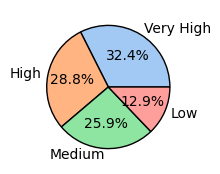

In [8]:
# Check the balance of target column Stress_Level
plt.figure(figsize=(2,2))
df['Stress_Level'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=sns.color_palette('pastel'),
                                       wedgeprops={'edgecolor': 'black', 'linewidth': 1})
plt.show()

The target variable Stress Level is almost equally distributed between Very High, High and Medium. However, the percentage of data with Low Stress Level is comparatively less than the other categories.

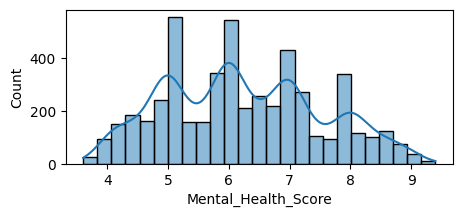

In [9]:
# Examine the distribution of Mental_Health_Score
plt.figure(figsize=(5,2))
sns.histplot(data=df, x='Mental_Health_Score', kde=True)
plt.show()

The distribution of Mental Health Score is a multimodal distribution with values ranginf from around 3 till 9. Multiple peaks have been observed at 5, 6, 7 and 8. The reason could be rounding off the values.

### Data Visualization

In [10]:
# Segregate the numerical, categorical columns from the target
num_cols = ['Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Study_Hours', 'Physical_Activity_Hours', 
            'Sleep_Hours_Per_Night', 'Screen_Nonscreen_Ratio', 'Unlocks_Per_Usage_Hour']
cat_cols = ['Age', 'Gender', 'Academic_Level', 'Most_Used_Platform', 'Purpose_Of_Use']
high_card_cat_cols = ['Country']
target1 = ['Stress_Level']
target2 = ['Mental_Health_Score']

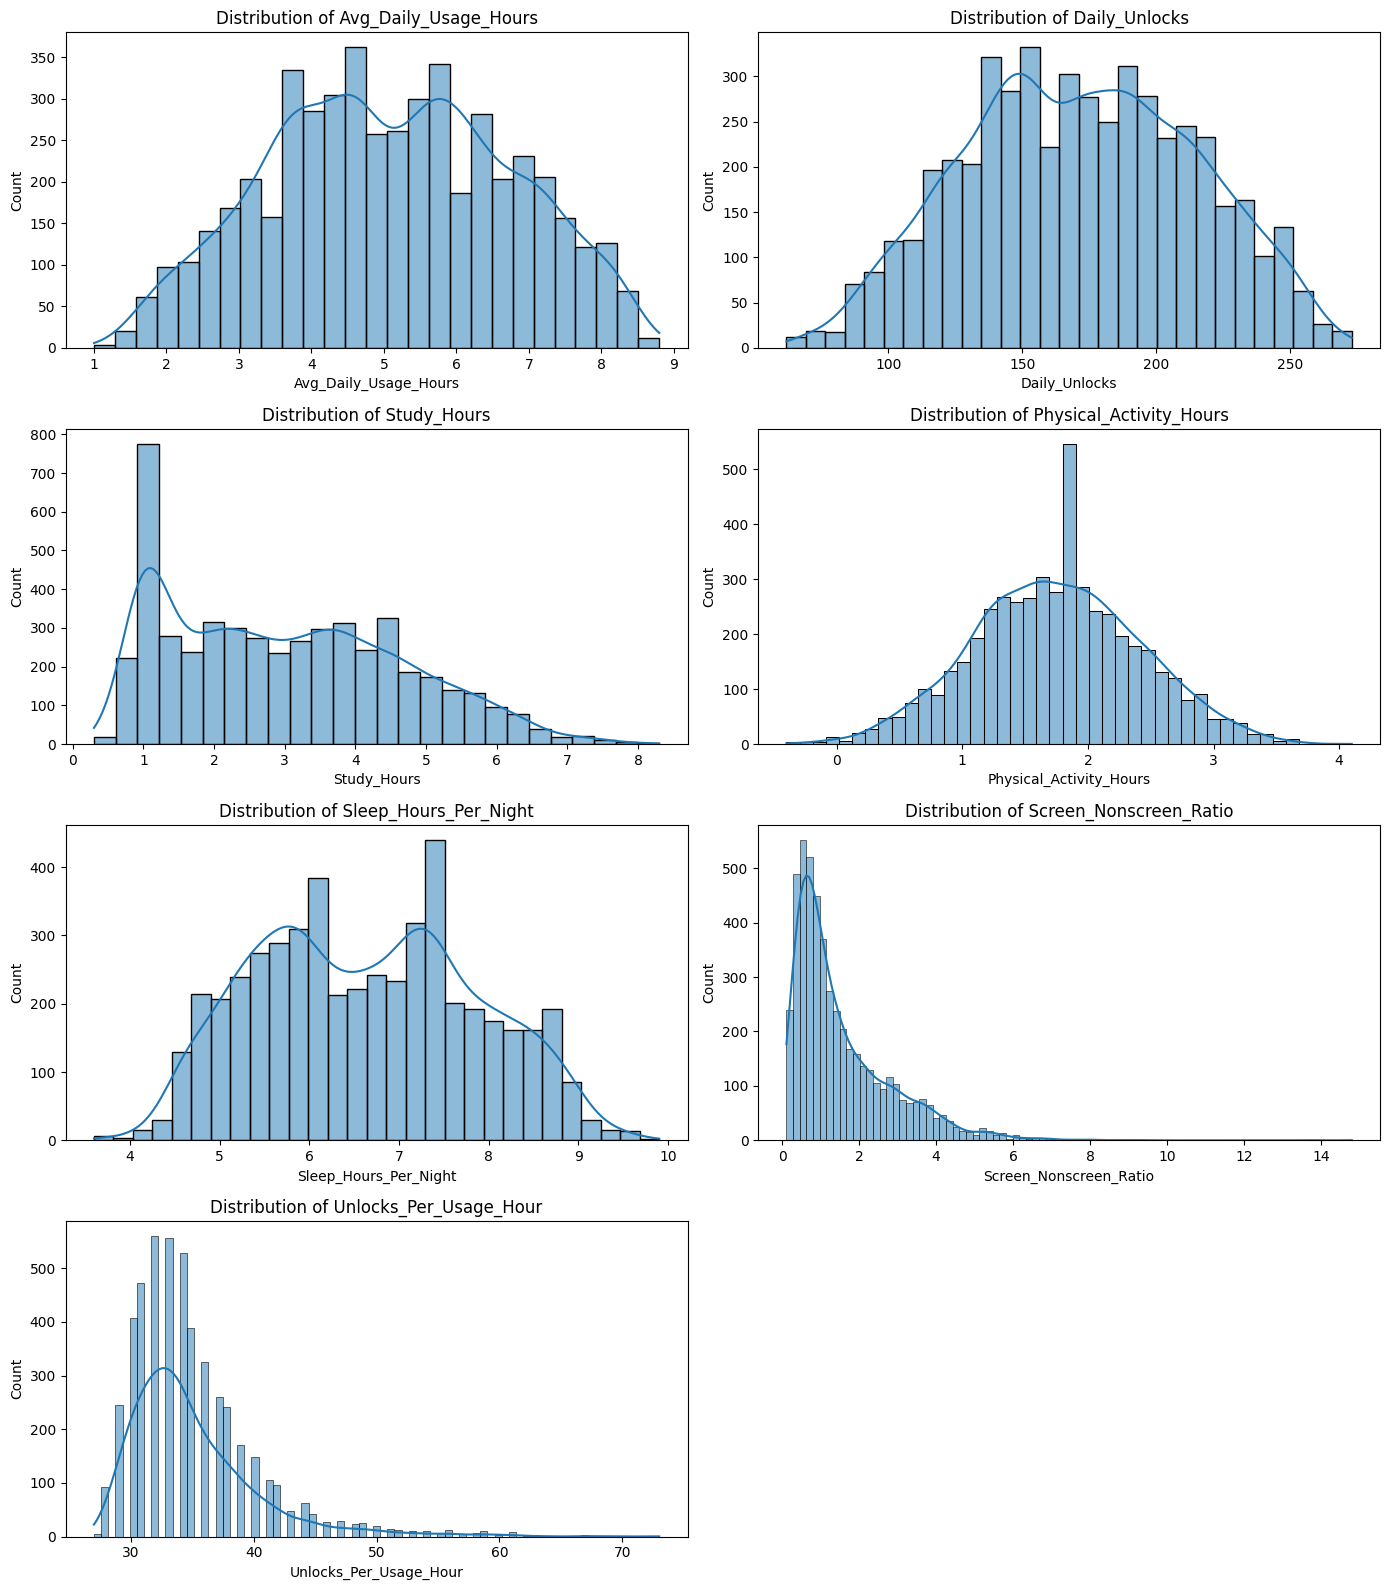

In [11]:
# Visualize the continous numerical columns using Histogram
no_of_rows = int((len(num_cols)+1)/2)
fig, axes = plt.subplots(no_of_rows, 2, figsize=(14, 4*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, ax=axes[i], kde=True)
    axes[i].set_title(f'Distribution of {col}')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

#### Insights:
1. Avg_Daily_Usage_Hours: The distribution is fairly spread across the observed range, with most users spending approximately 3 to 7 hours per day. There is no strong skewness, although multiple local peaks are visible, indicating variation in daily usage patterns.

2. Daily_Unlocks: Daily unlock frequency shows a relatively broad and approximately symmetric distribution, with most observations concentrated around 120–220 unlocks per day. No pronounced long tail is visible.

3. Study_Hours: Study hours show a right-skewed distribution, with a noticeable concentration near 1 hour and progressively fewer observations at higher study durations. A small number of observations extend beyond 6 hours.

4. Physical_Activity_Hours: Physical activity appears comparatively symmetric and bell-shaped, centered roughly around 1.5–2 hours per day. A noticeable frequency spike is present around this region and should be checked using value counts to determine whether it results from repeated/rounded values.

5. Sleep_Hours_Per_Night: Sleep duration ranges approximately from 3.5 to 10 hours, with most observations lying between about 5 and 9 hours. The distribution appears to have more than one peak, suggesting that different sleep-duration patterns may exist within the dataset.

6. Screen_Nonscreen_Ratio: The engineered ratio is strongly right-skewed. Most observations are concentrated at relatively low ratios, while a small number extend to much larger values, forming a long right tail. These high values should be investigated before treating them as outliers because ratio features can naturally become large when their denominator is small.

7. Unlocks_Per_Usage_Hour: This engineered feature is also positively/right-skewed. Most observations are concentrated approximately between 30 and 40 unlocks per usage hour, while a smaller number of observations extend beyond 50 and toward 70+. The extreme values should be examined against Daily_Unlocks and Avg_Daily_Usage_Hours before deciding whether any outlier treatment is necessary.

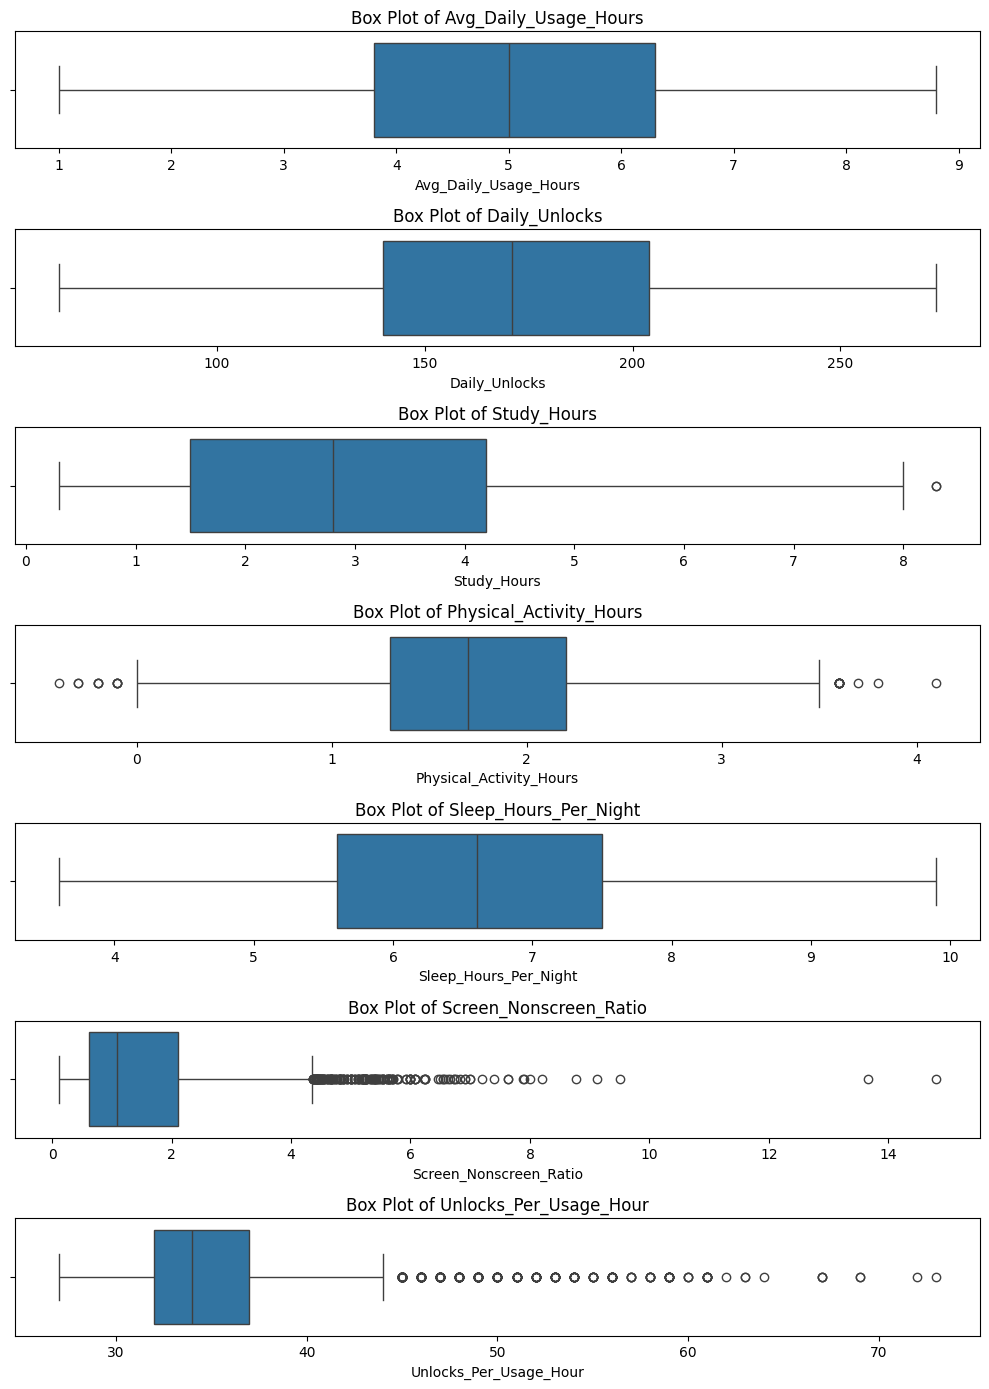

In [12]:
# Detect the outliers using boxplot
no_of_rows = len(num_cols)
fig, axes = plt.subplots(no_of_rows, 1, figsize=(10, 2*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Box Plot of {col}')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

No major outliers found in the initial features of the dataset. However, some outliers are observed in the derived features. These outliers doesn't seem to be erronous and can be kept for further analysis.

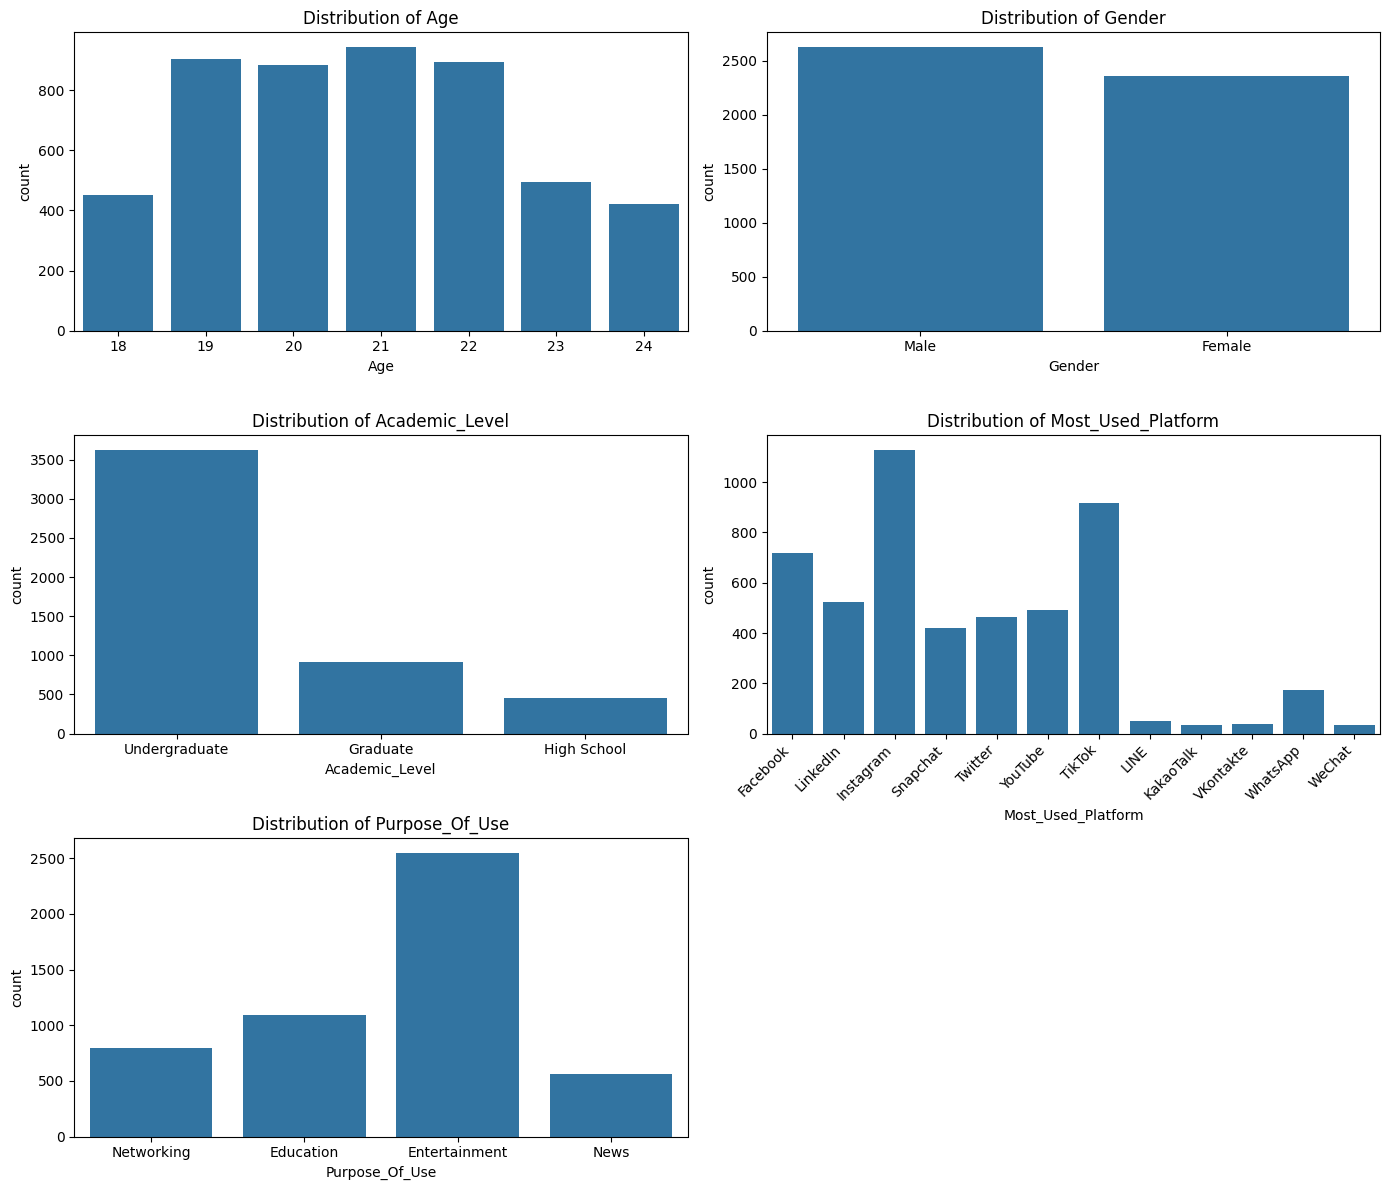

In [13]:
# Visualize the categorical columns using Countplot
no_of_rows = int((len(cat_cols)+1)/2)
fig, axes = plt.subplots(no_of_rows, 2, figsize=(14, 4*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    if col in ['Most_Used_Platform']:
        plt.setp(axes[i].get_xticklabels(), rotation=45, ha='right')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

#### Insights:
1. Age: The dataset contains individuals aged 18–24 years, with the highest representation around 19–22 years. Ages 18, 23, and 24 are comparatively less represented.
2. Gender: The two gender categories are fairly balanced, although the Male category has a moderately higher number of observations than the Female category.
3. Academic Level: The dataset is heavily dominated by Undergraduate students, while Graduate and High School students have substantially fewer observations, indicating an imbalanced academic-level distribution.
4. Most Used Platform: Instagram and TikTok are the most frequently used platforms, followed by Facebook. Platforms such as LINE, KakaoTalk, VKontakte, and WeChat have very few observations, indicating a highly uneven platform distribution.
5. Purpose of Use: Entertainment is the dominant purpose of social-media use, followed by Education and Networking, while News is the least represented purpose.

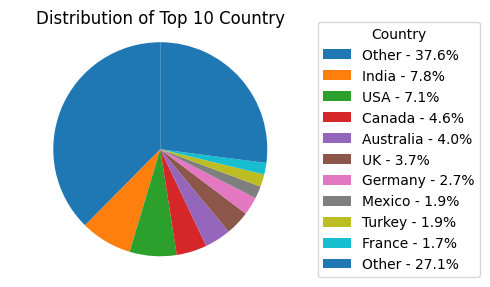

In [14]:
# Distribution of High Cardinality Categorical columns
for col in high_card_cat_cols:
    # Top 10 countries + Other
    counts = df[col].value_counts()
    top_10 = counts.head(10)
    others = counts.iloc[10:].sum()
    plot_data = pd.concat([top_10, pd.Series({'Other': others})])

    # Calculate the percentages
    percentages = plot_data / plot_data.sum() * 100
   
    # Create labels with country + percentage
    labels = [f'{name} - {percentage:.1f}%' for name, percentage in zip(plot_data.index, percentages)]
    
    # Plot
    fig, ax = plt.subplots(figsize=(5, 3))
    wedges, _ = ax.pie(plot_data.values, startangle=90)
    ax.legend(wedges, labels, title=col, loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
    ax.set_title(f'Distribution of Top 10 {col}')
    ax.axis('equal')
    plt.tight_layout()
    plt.show()

The original Other category (means the country is not known) represents 37.6% of the dataset, making it the largest individual category, followed by India (7.8%) and USA (7.1%).
The countries outside the top 10 collectively represent 27.1% of observations, confirming that Country is a high-cardinality and widely dispersed feature with many less-frequent categories.

### Relation between Features and Target

#### 1. Numerical Columns vs Stress Level

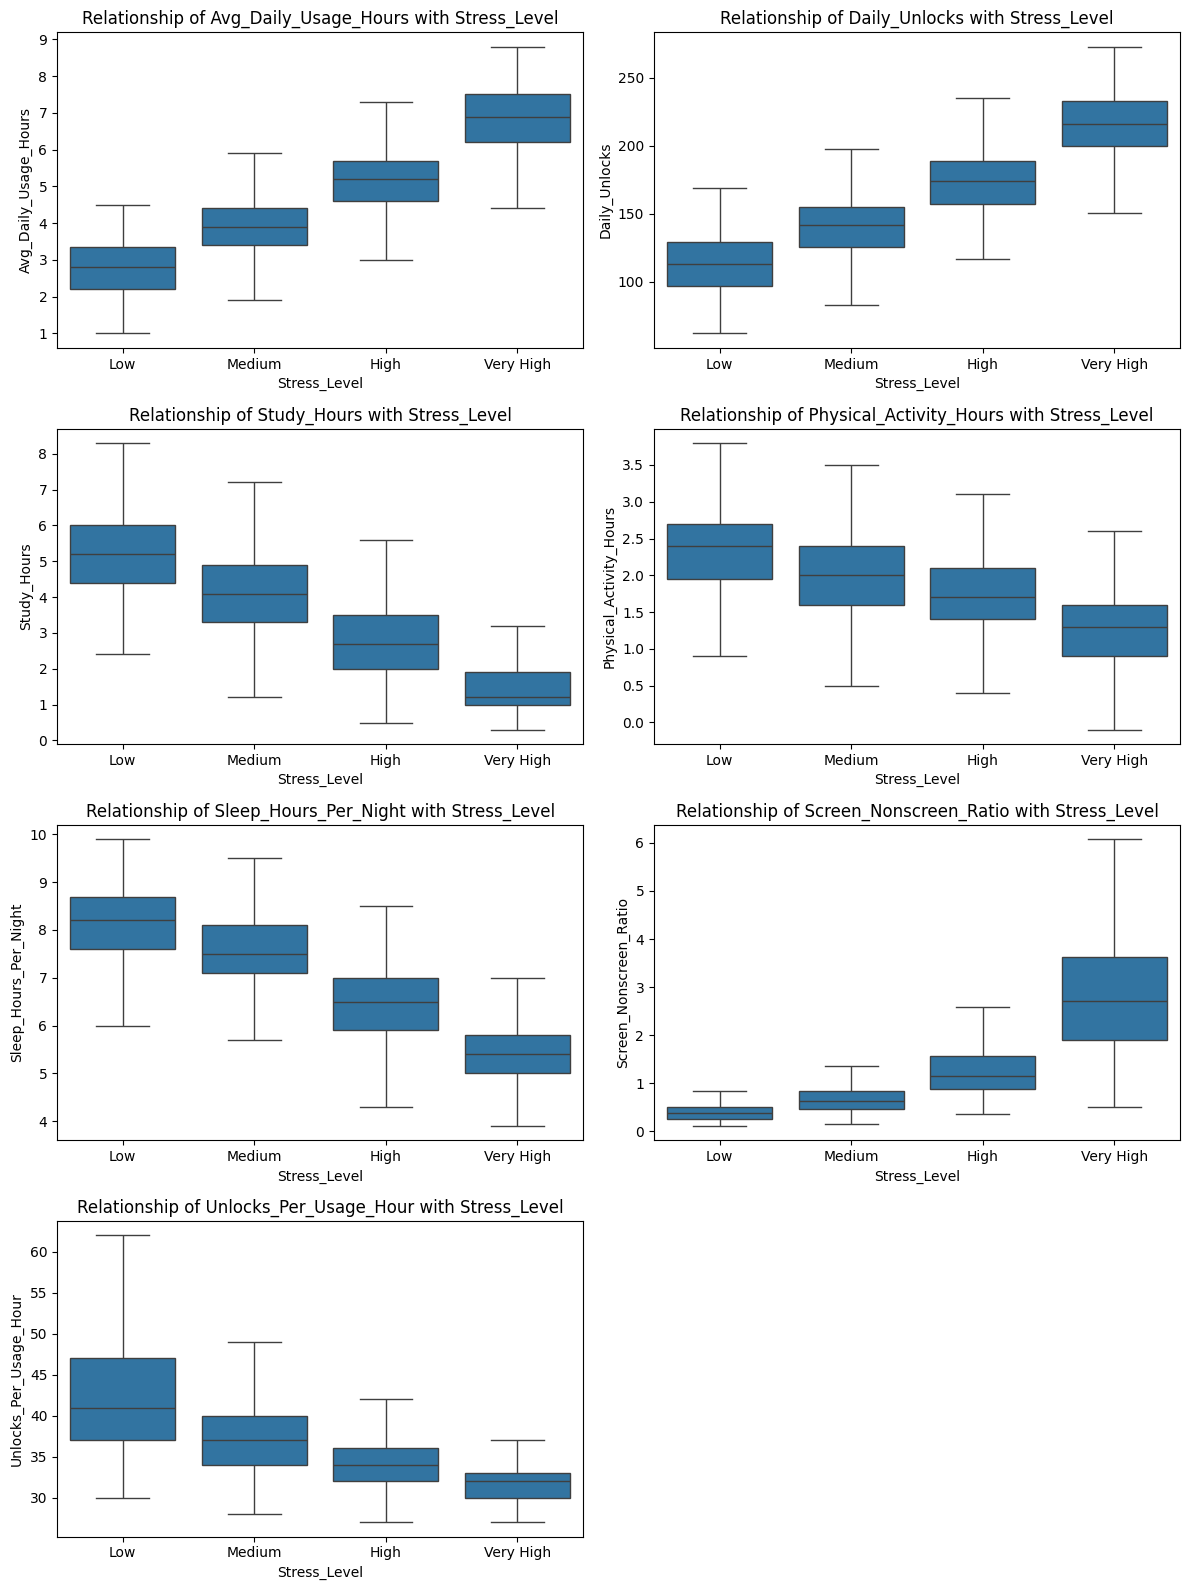

In [15]:
# Find the relation between numerical columns with Stress Level using Boxplot
no_of_rows = (len(num_cols)+1)//2
stress_order = ['Low', 'Medium', 'High', 'Very High']
fig, axes = plt.subplots(no_of_rows, 2, figsize=(12, 4*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(data=df[num_cols+target1], x=target1[0], y=col, showfliers=False, ax=axes[i], order=stress_order)
    axes[i].set_title(f'Relationship of {col} with {target1[0]}')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

1. The stress level increases from low to very high with increase in average daily usage, daily unloacks, screen to non screen ratio.
2. The stress level increases from low to very high with decrease in study hours, physical activity hours, sleep hours and unlock per usage hours.

#### 2. Numerical Columns vs Mental Health Score

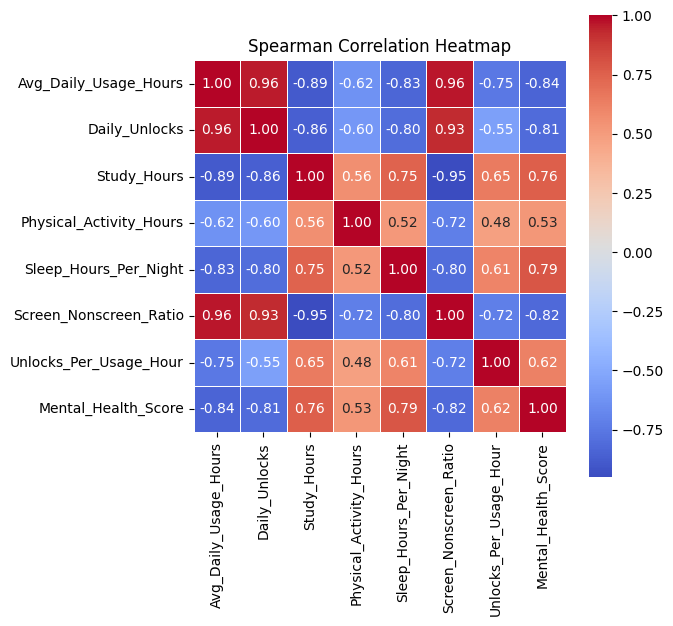

In [16]:
# Find the relation between numerical columns with Mental Health Score using Correlation Heatmap
plt.figure(figsize=(6,6))
corr_matrix = df[num_cols+target2].corr(method='spearman')
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Spearman Correlation Heatmap')
plt.show()

#### Insights:
1. Sleep_Hours_Per_Night shows a strong positive correlation (0.79) with Mental_Health_Score, suggesting students with higher sleep duration tend to have better mental health scores.
2. Study_Hours has a strong positive correlation (0.76) with Mental_Health_Score, indicating that students who spend more time studying generally exhibit higher mental health scores.
3. Physical_Activity_Hours demonstrates a moderate positive relationship (0.53) with Mental_Health_Score, suggesting that increased physical activity may be associated with improved mental well-being.
4. Unlocks_Per_Usage_Hour shows a moderate positive correlation (0.62), indicating that frequent but shorter phone interactions may be less detrimental than prolonged screen usage.
5. Avg_Daily_Usage_Hours exhibits a strong negative correlation (-0.84) with Mental_Health_Score, indicating that excessive daily screen time is associated with poorer mental health outcomes.
6. Daily_Unlocks also shows a strong negative relationship (-0.81), suggesting that frequent phone checking behavior may be linked to lower mental health scores.
7. Screen_Nonscreen_Ratio shows a strong negative correlation (-0.82) with Mental_Health_Score, indicating that higher screen exposure relative to non-screen activities is associated with poorer mental health.

#### 3. Categorical Columns vs Stress Level

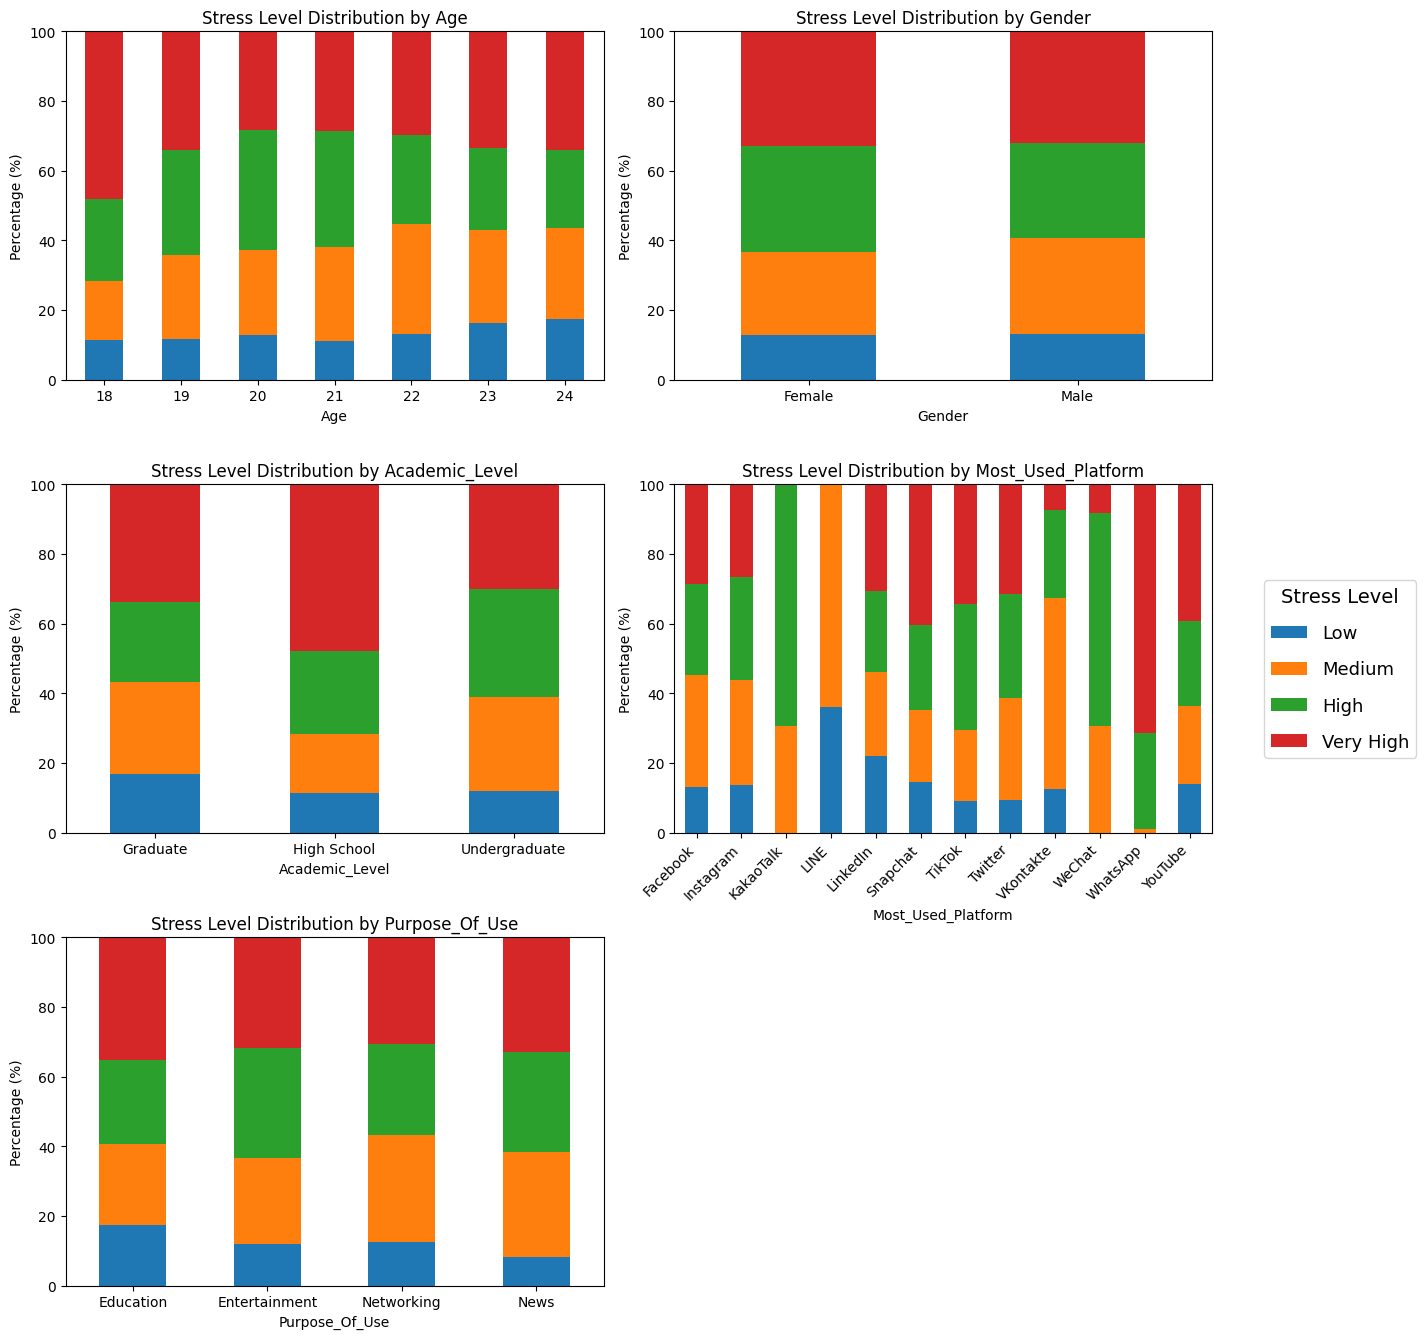

In [17]:
# Find the relation between categorical columns with Stress Level using normalized stacked bar plots
stress_order = ['Low', 'Medium', 'High', 'Very High']
no_of_rows = (len(cat_cols) + 1) // 2
fig, axes = plt.subplots(no_of_rows, 2, figsize=(14, 4.5*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    # Calculate percentage distribution within each category
    temp = pd.crosstab(df[col], df['Stress_Level'], normalize='index')[stress_order] * 100
    # Plot on corresponding subplot
    temp.plot(kind='bar', stacked=True, ax=axes[i], legend=False)
    axes[i].set_title(f'Stress Level Distribution by {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Percentage (%)')
    axes[i].set_ylim(0, 100)
    # Rotate only selected columns
    if col in ['Most_Used_Platform']:
        axes[i].tick_params(axis='x', labelrotation=45)
        for label in axes[i].get_xticklabels():
            label.set_ha('right')
    else:
        # Keep other labels horizontal
        axes[i].tick_params(axis='x', labelrotation=0)
        
# Remove unused subplot(s)
for j in range(len(cat_cols), len(axes)):
    fig.delaxes(axes[j])
    
# One common legend for all graphs
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='Stress Level', loc='center left', bbox_to_anchor=(0.9, 0.5), fontsize=13, 
           title_fontsize=14, labelspacing=1.0, handlelength=2)

# Leave space on the right for legend
plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.show()

#### Insights
1. Age: The proportion of Very High stress is highest among 18-year-olds, decreases across the middle age groups, and shows a slight increase around ages 23–24. Age shows some variation across stress categories and may provide useful predictive information, which should be validated during modeling.
2. Gender: Stress-level distributions are very similar across the gender categories, with only minor differences in the proportions of Low, Medium, High, and Very High stress. Gender therefore shows limited standalone association with Stress Level in the EDA.
3. Academic Level: High School students show the highest proportion of Very High stress, while the Graduate group shows the highest proportion of Low stress among the three groups. Academic Level therefore shows noticeable variation across stress categories.
4. Most Used Platform: Stress-level proportions vary considerably across social-media platforms, suggesting that Most_Used_Platform may contain predictive information. However, extreme patterns among low-frequency platforms should be interpreted cautiously because they are based on relatively small sample sizes.
5. Purpose of Use: Stress-level distributions are relatively similar across Education, Entertainment, Networking, and News, with only moderate differences between categories. Purpose_Of_Use therefore appears to have a limited standalone association with Stress Level based on the current visualization.

#### 4. Categorical Columns vs Mental Health Score

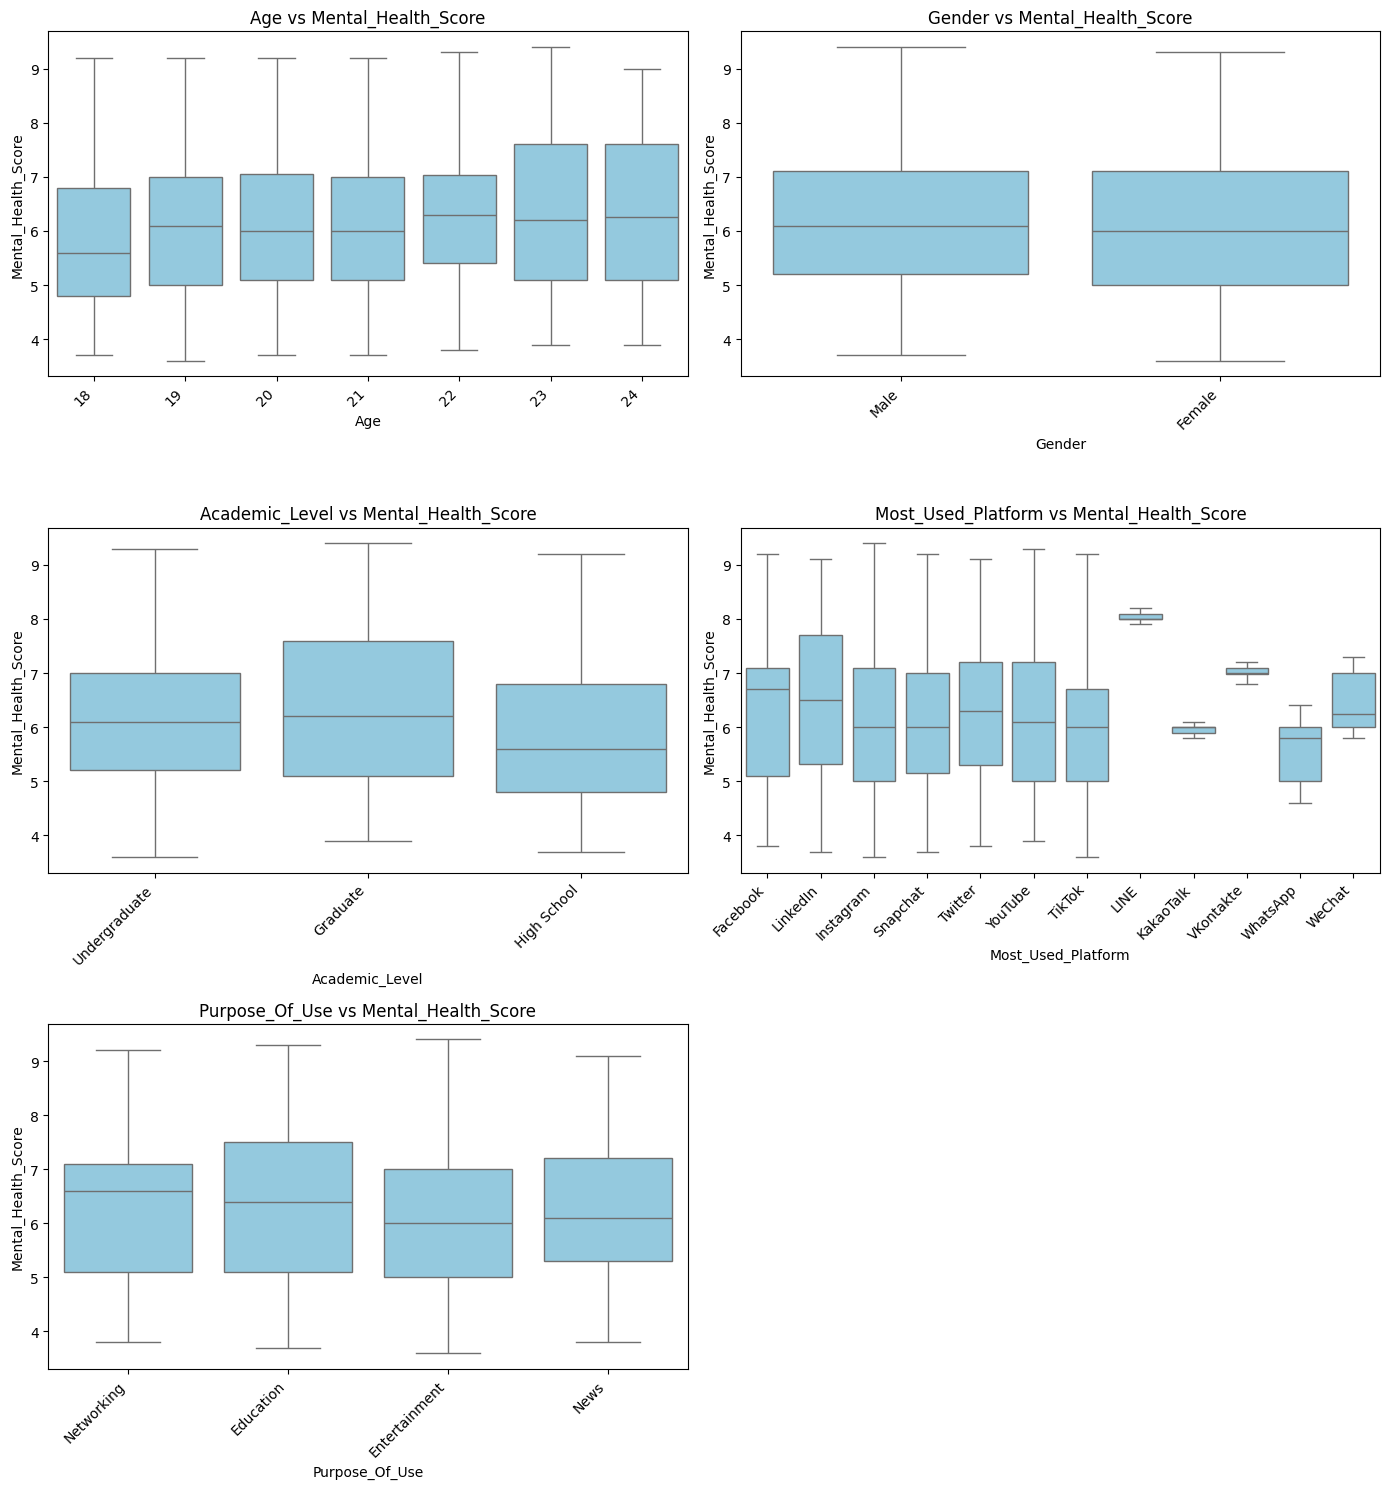

In [18]:
# Find the relation between categorical columns with Mental Health Score using Boxplot
no_of_rows = (len(cat_cols)+1)//2
fig, axes = plt.subplots(no_of_rows, 2, figsize=(14, 5*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    sns.boxplot(data=df, x=col, y=target2[0], showfliers=False, color='skyblue', ax=axes[i])
    axes[i].set_title(f'{col} vs {target2[0]}')
    plt.setp(axes[i].get_xticklabels(), rotation=45, ha='right')
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

#### Insights:
1. Academic_Level vs Mental_Health_Score : Graduate students show a slightly higher median Mental_Health_Score compared to Undergraduate and High School students. However, the distributions largely overlap, indicating that Academic_Level alone may not strongly differentiate mental health outcomes.

2. Most_Used_Platform vs Mental_Health_Score : Most platforms exhibit similar score distributions, with median Mental_Health_Scores generally ranging between 6 and 7. Some platforms (e.g., LINE and VKontakte) appear to have higher median scores, but these groups also seem to have very small sample sizes. Overall, platform preference appears to have a limited standalone association with Mental_Health_Score.

3. Purpose_Of_Use vs Mental_Health_Score : Students using social media primarily for Education and Networking show slightly higher median Mental_Health_Scores than those using it mainly for Entertainment. The substantial overlap among distributions suggests that Purpose_Of_Use is not a strong individual predictor.

4. Age vs Mental_Health_Score : Median Mental_Health_Score shows a slight upward trend from ages 18 to 24. Differences across age groups are relatively small, indicating a weak relationship between Age and Mental_Health_Score.

5. Gender vs Mental_Health_Score : Male and Female groups exhibit nearly identical median scores and distribution ranges. This suggests Gender may have limited predictive power for Mental_Health_Score in this dataset.

#### 5. High Cardinality Categorical Columns vs Stress Level

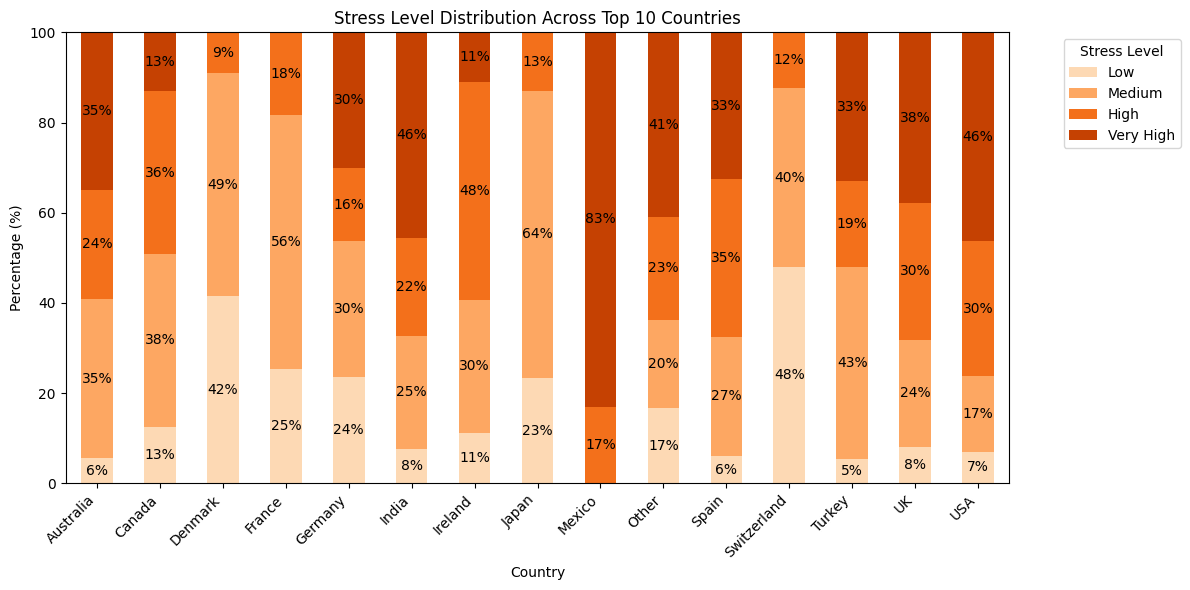

In [19]:
# Find the relation between high cardinality categorical columns with Stress Level using Stacked Percentage Bar Chart
stress_order = ['Low', 'Medium', 'High', 'Very High']
top15_countries = df['Country'].value_counts().head(15).index # Top 15 countries
temp = df[df['Country'].isin(top15_countries)]
country_stress_pct = (pd.crosstab(temp['Country'], temp['Stress_Level'], normalize='index')*100)
country_stress_pct = country_stress_pct[stress_order] # Ensure correct stress level order

# Plot
ax = country_stress_pct.plot(kind='bar', stacked=True, figsize=(12,6), color = sns.color_palette("Oranges",4))

for container in ax.containers:
    labels = [f'{v:.0f}%' if v > 0 else '' for v in container.datavalues]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=10)

plt.title('Stress Level Distribution Across Top 10 Countries')
plt.xlabel('Country')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Stress Level', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### Insights:
1. Stress level distributions vary substantially across countries, indicating potential geographical differences in stress patterns.
2. Mexico, India, USA, UK, and Australia show higher proportions of Very High Stress individuals. However, Switzerland, Denmark, Japan, and France exhibit larger proportions of Low and Medium Stress levels.
3. Country may provide useful predictive information for Stress_Level, although stress categories are represented across most countries.

#### 6. High Cardinality Categorical Columns vs Mental Health Score

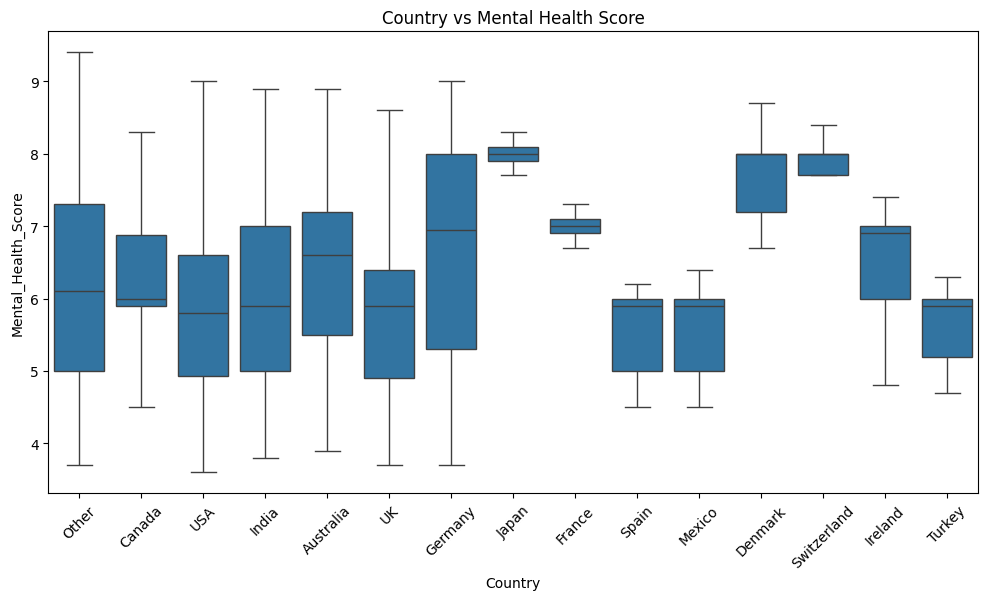

In [20]:
# Find the relation between high cardinality categorical columns with Stress Level using Mean Score Bar Chart
top15_countries = df['Country'].value_counts().head(15).index
temp = df[df['Country'].isin(top15_countries)]
plt.figure(figsize=(12, 6))
sns.boxplot(data=temp, x='Country', y='Mental_Health_Score', showfliers=False)
plt.xticks(rotation=45)
plt.title('Country vs Mental Health Score')
plt.show()

#### Insights:
1. Japan has the highest average Mental_Health_Score (≈ 8.0), followed by Switzerland and Denmark (≈ 7.7-7.8), indicating relatively better mental health outcomes among students in these countries.
2. France, Germany, Ireland, and Australia form a middle group with average scores ranging from approximately 6.4 to 6.9.
3. Mexico, Spain, and Turkey exhibit the lowest average Mental_Health_Scores (≈ 5.6-5.7), indicating comparatively poorer mental health outcomes within the analyzed countries.
4. Countries with higher average Mental_Health_Scores generally correspond to countries that showed larger proportions of Low and Medium stress levels in the previous stress-distribution analysis.

In [21]:
# Perform ANOVA Test to check if the mental health score is significantly different among the different countries.
# H0 (Null Hypothesis): All countries have the same mean Mental_Health_Score.
# H1 (Alternative Hypothesis): At least one country's mean Mental_Health_Score is significantly different.

top_countries = df['Country'].value_counts().head(15).index
temp = df[df['Country'].isin(top_countries)]
groups = [group['Mental_Health_Score'].values for _, group in temp.groupby('Country')]
f_stat, p_value = f_oneway(*groups)
print(f"F-statistic: {f_stat:.4f}")
print(f"p-value: {p_value:.6f}")

# Interpretation Results
alpha = 0.05
if p_value < alpha:
    print("Significant differences exist between countries.")
else:
    print("No statistically significant difference between countries.")

F-statistic: 39.7539
p-value: 0.000000
Significant differences exist between countries.


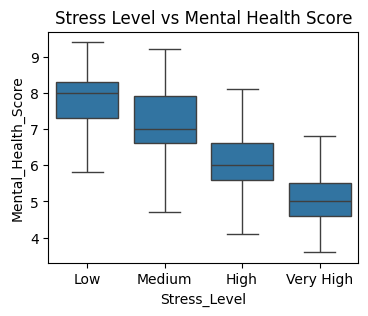

In [22]:
# Relation between both the targets
stress_order = ['Low', 'Medium', 'High', 'Very High']
plt.figure(figsize=(4, 3))
sns.boxplot(data=df, x='Stress_Level', y='Mental_Health_Score', showfliers=False, order=stress_order)
plt.title('Stress Level vs Mental Health Score')
plt.show()

Both the targets are inversely proportional to each other. When the stress level decreases, the mental health score increases.

In [23]:
# Group rare countries
country_counts = df['Country'].value_counts()
rare_countries = country_counts[country_counts<10].index
df['Country'] = df['Country'].replace(rare_countries, 'Other')

### Create Baseline Models - Random Forest

In [24]:
# Define features and target
x = df.drop(['Stress_Level', 'Mental_Health_Score'], axis=1)
y_mhs = df['Mental_Health_Score']
y_stress = df['Stress_Level']

In [25]:
# Define the columns for encoding and standard scaling
col_to_encode = ['Gender', 'Country', 'Academic_Level', 'Most_Used_Platform', 'Purpose_Of_Use']
col_to_scale = ['Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Study_Hours', 'Physical_Activity_Hours', 
                'Sleep_Hours_Per_Night', 'Screen_Nonscreen_Ratio', 'Unlocks_Per_Usage_Hour']

In [26]:
# Build a pipeline for data preprocessing of Random Forest Algorithm
prepr_rf = ColumnTransformer(transformers=[('num', 'passthrough', col_to_scale), 
                        ('cat', Pipeline([('onehot', OneHotEncoder(handle_unknown='ignore'))]), col_to_encode)])

In [27]:
# Train Test Split for Stress Level Prediction
x_train_stress, x_test_stress, y_train_stress, y_test_stress = train_test_split(x, y_stress, test_size=0.2, 
                                                                            random_state=42, stratify=y_stress)
# Train Test Split for Mental Health Score Prediction
x_train_mhs, x_test_mhs, y_train_mhs, y_test_mhs = train_test_split(x, y_mhs, test_size=0.2, random_state=42)

#### Train Random Forest Classifier (Stress_Level)

In [28]:
# Use Random Forest Classifier Algorithm to predict Stress Level
rf_stress = Pipeline([('preprocessor', prepr_rf), 
                      ('classifier', RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))])
rf_stress.fit(x_train_stress, y_train_stress)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['High','Low','Medium','Very High']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Age','Gender','Country',...,'Sleep_Hours_Per_Night', 'Screen_Nonscreen_Ratio','Unlocks_Per_Usage_Hour']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (

#### Evaluate Random Forest Classifier (Stress_Level)

In [29]:
# Predict the output
y_pred_stress = rf_stress.predict(x_test_stress)

In [30]:
# Calculate the accuracy and F1 score
accuracy = accuracy_score(y_test_stress, y_pred_stress)
test_f1 = f1_score(y_test_stress, y_pred_stress, average='weighted')
print("Accuracy:", round(accuracy, 3))
print("Test F1 Score:", round(test_f1, 3))

Accuracy: 0.899
Test F1 Score: 0.899


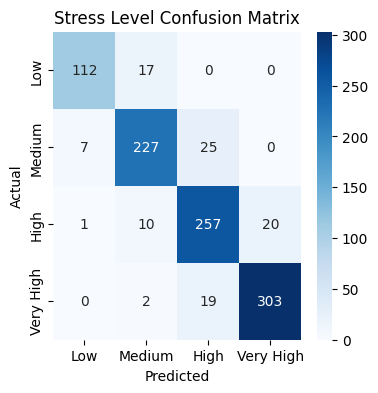

In [31]:
# Plot the confusion matrix
stress_order = ['Low', 'Medium', 'High', 'Very High']
cm = confusion_matrix(y_test_stress, y_pred_stress, labels=stress_order)

plt.figure(figsize=(4,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=stress_order, yticklabels=stress_order)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Stress Level Confusion Matrix")
plt.show()

The Random Forest Classifier achieved an accuracy of 89.9%. Analysis of the confusion matrix indicates that the majority of observations were correctly classified. Misclassifications primarily occurred between adjacent stress categories (e.g., Medium and High), while extreme misclassifications were virtually absent. This demonstrates the model's ability to effectively capture stress level patterns while maintaining logical prediction consistency.

#### Train Random Forest Classifier (Mental_Health_Score)

In [32]:
# Use Random Forest Regressor Algorithm to predict Mental Health Score
rf_mhs = Pipeline([('preprocessor', prepr_rf), 
                   ('regressor', RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))])
rf_mhs.fit(x_train_mhs, y_train_mhs)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Age','Gender','Country',...,'Sleep_Hours_Per_Night', 'Screen_Nonscreen_Ratio','Unlocks_Per_Usage_Hour']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically 

#### Evaluate Random Forest Regressor (Mental_Health_Score)

In [33]:
# Predict the results
y_pred_mhs = rf_mhs.predict(x_test_mhs)

In [34]:
# Calculate the Evaluation Parameters
mae = mean_absolute_error(y_test_mhs, y_pred_mhs)
rmse = root_mean_squared_error(y_test_mhs, y_pred_mhs)
r2 = r2_score(y_test_mhs, y_pred_mhs)
print(f'Mean Absolute Error: {round(mae,2)} \nRoot Mean Squared Error: {round(rmse,2)} \nR2 Score: {round(r2,2)}')

Mean Absolute Error: 0.29 
Root Mean Squared Error: 0.4 
R2 Score: 0.91


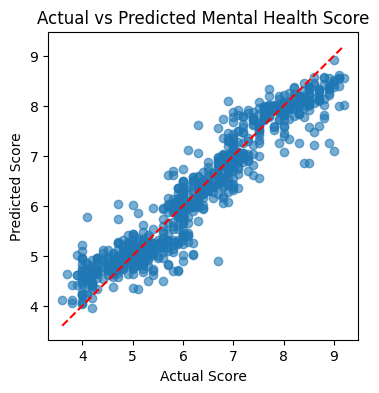

In [35]:
# Actual vs Prediction Plot
plt.figure(figsize=(4,4))
plt.scatter(y_test_mhs, y_pred_mhs, alpha=0.6)
plt.plot([y_test_mhs.min(), y_test_mhs.max()], [y_test_mhs.min(), y_test_mhs.max()], 'r--')
plt.xlabel("Actual Score")
plt.ylabel("Predicted Score")
plt.title("Actual vs Predicted Mental Health Score")
plt.show()

The Actual vs Predicted plot demonstrates strong agreement between observed and predicted mental health scores. Most data points lie close to the ideal prediction line, indicating high predictive accuracy and minimal prediction bias. The strong clustering around the diagonal further supports the high R² score of 0.91.

### Feature Importance Analysis

#### 1. For Stress Level

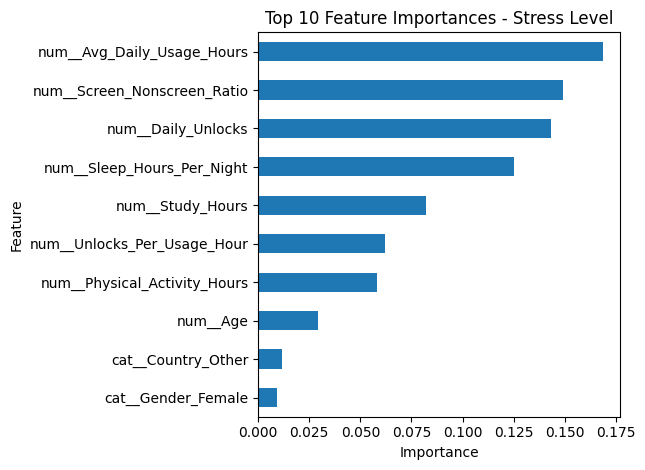

In [36]:
# Get the top 10 important feature names
feature_names = rf_stress.named_steps['preprocessor'].get_feature_names_out()
importances = rf_stress.named_steps['classifier'].feature_importances_
stress_importance = pd.DataFrame({'Feature': feature_names, 
                                  'Importance': importances}).sort_values('Importance', ascending=False)
stress_importance.head(10).sort_values('Importance').plot(x='Feature', y='Importance', kind='barh', legend=False)
plt.title('Top 10 Feature Importances - Stress Level')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

Average daily screen usage, phone unlock frequency, screen-to-non-screen ratio, sleep duration, and study hours were the most influential features for predicting stress levels. Feature importance was distributed across multiple behavioral attributes, suggesting that stress is driven by a combination of lifestyle and digital usage factors rather than a single dominant variable.

#### 2. For Mental Health Score 

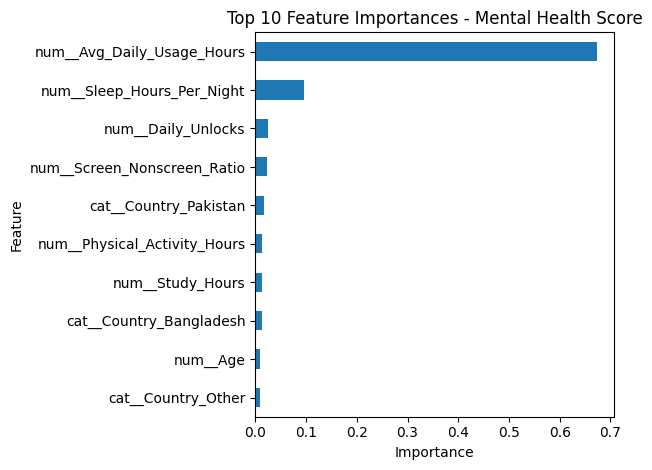

In [37]:
# Get the top 10 important feature names
feature_names = rf_mhs.named_steps['preprocessor'].get_feature_names_out()
importances = rf_mhs.named_steps['regressor'].feature_importances_
mhs_importance = pd.DataFrame({'Feature': feature_names, 
                               'Importance': importances}).sort_values('Importance', ascending=False)
mhs_importance.head(10).sort_values('Importance').plot(x='Feature', y='Importance', kind='barh', legend=False)
plt.title('Top 10 Feature Importances - Mental Health Score')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

For Mental Health Score model, we see that the feature Avg_Daily_Usage_Hours and Sleep_Hours_Per_Night alone contributes nearly 75% of the model's prediction power. Feature importance from the Random Forest model highlighted Average Daily Usage Hours and Sleep Hours as the dominant predictors. The heatmap results showed substantial multicollinearity among screen usage, unlock frequency, and sleep-related variables, suggesting that Average Daily Usage Hours captures a large portion of the predictive information shared across these features.

5 fold cross validation will be performed on the pipeline to ensure preprocessing is applied separately within each fold and avoids data leakage

### Cross Validation Score

In [38]:
# Calculate the cross validation metrics for Stress Level Prediction
cv_acc = cross_val_score(rf_stress, x_train_stress, y_train_stress, cv=5, scoring='accuracy', n_jobs=-1)
cv_f1 = cross_val_score(rf_stress, x_train_stress, y_train_stress, cv=5, scoring='f1_weighted', n_jobs=-1)

print("Mean Accuracy:", round(np.mean(cv_acc), 3))
print("Mean F1:", round(np.mean(cv_f1), 3))

Mean Accuracy: 0.871
Mean F1: 0.87


In [39]:
# Calculate the cross validation metrics for Mental Health Score Prediction
cv_r2 = cross_val_score(rf_mhs, x_train_mhs, y_train_mhs, cv=5, scoring='r2', n_jobs=-1)
cv_rmse = -cross_val_score(rf_mhs, x_train_mhs, y_train_mhs, cv=5, scoring='neg_root_mean_squared_error', 
                           n_jobs=-1)
print("Mean RMSE:", round(np.mean(cv_rmse), 3))
print("Mean R²:", round(np.mean(cv_r2), 3))

Mean RMSE: 0.416
Mean R²: 0.891


### Check for Overfitting

In [40]:
train_acc = rf_stress.score(x_train_stress, y_train_stress)
test_acc = rf_stress.score(x_test_stress, y_test_stress)
fit_stress = ('No Overfit' if abs(train_acc-test_acc) <= 0.04 else 
              'Slight Overfit' if abs(train_acc-test_acc) <= 0.08 else 
              'Moderate Overfit' if abs(train_acc-test_acc) <= 0.12 else 'Significant Overfit')
print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)
print('Fit:', fit_stress)

Train Accuracy: 1.0
Test Accuracy: 0.899
Fit: Moderate Overfit


In [41]:
train_pred = rf_mhs.predict(x_train_mhs)
test_pred = rf_mhs.predict(x_test_mhs)
train_r2 = r2_score(y_train_mhs, train_pred)
test_r2 = r2_score(y_test_mhs, test_pred)
fit_mhs = ('No Overfit' if abs(train_r2-test_r2) <= 0.04 else 
           'Slight Overfit' if abs(train_r2-test_r2) <= 0.08 else 
           'Moderate Overfit' if abs(train_r2-test_r2) <= 0.12 else 'Significant Overfit')
print("Train R²:", round(train_r2, 3))
print("Test R² :", round(test_r2, 3))
print('Fit:', fit_mhs)

Train R²: 0.987
Test R² : 0.912
Fit: Slight Overfit


### Display the reults of Baseline model

In [42]:
# For Stress Level Prediction
stress_results = []
stress_results.append({'Model': 'Random Forest', 'Accuracy': round(accuracy,3), 
                       'Test F1 Score': round(test_f1,3), 'CV Mean Accuracy': round(np.mean(cv_acc),3),
                       'CV Mean F1 Score': round(np.mean(cv_f1),3), 'Train Accuracy': train_acc,
                       'Test Accuracy': test_acc, 'Overfitting': fit_stress})
stress_summary_df = pd.DataFrame(stress_results)
stress_summary_df

,Model,Accuracy,Test F1 Score,CV Mean Accuracy,CV Mean F1 Score,Train Accuracy,Test Accuracy,Overfitting
0,Random Forest,0.899,0.899,0.871,0.87,1.0,0.899,Moderate Overfit


In [43]:
# For Mental Health Score Prediction
mhs_results = []
mhs_results.append({'Model': 'Random Forest', 'Mean Absolute Error': round(mae,3), 
                    'Root Mean Squared Error': round(rmse,2), 'R² Score': round(r2,2), 
                    'CV Mean RMSE': round(np.mean(cv_rmse), 3), 'CV Mean R² Score': round(np.mean(cv_r2), 3), 
                    'Train R² Score': round(train_r2, 3), 'Test R² Score': round(test_r2, 3), 
                    'Overfitting': fit_mhs})
mhs_summary_df = pd.DataFrame(mhs_results)
mhs_summary_df

,Model,Mean Absolute Error,Root Mean Squared Error,R² Score,CV Mean RMSE,CV Mean R² Score,Train R² Score,Test R² Score,Overfitting
0,Random Forest,0.285,0.4,0.91,0.416,0.891,0.987,0.912,Slight Overfit


### Create Advanced Models - XG Boost

In [44]:
# Using Label Encoder encode the target variable
stress_map = {'Low': 0, 'Medium': 1, 'High': 2, 'Very High': 3}
y_train_stress_enc = y_train_stress.map(stress_map)
y_test_stress_enc = y_test_stress.map(stress_map)

#### Train XGBoost Classifier (Stress_Level)

In [45]:
# Use XGBoost Classifier to predict the Stress Level
xgb_stress = Pipeline([('preprocessor', prepr_rf), 
                       ('classifier', XGBClassifier(n_estimators=200, random_state=42, eval_metric='mlogloss'))])
xgb_stress.fit(x_train_stress, y_train_stress_enc)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Age','Gender','Country',...,'Sleep_Hours_Per_Night', 'Screen_Nonscreen_Ratio','Unlocks_Per_Usage_Hour']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By s

#### Evaluate XGBoost Classifier (Stress_Level)

In [46]:
# Predict the output
reverse_stress_map = {0: 'Low', 1: 'Medium', 2: 'High', 3: 'Very High'}
y_pred_num = xgb_stress.predict(x_test_stress)
y_pred_stress = pd.Series(y_pred_num).map(reverse_stress_map)

In [47]:
# Calculate the accuracy and F1 score
accuracy = accuracy_score(y_test_stress, y_pred_stress)
test_f1 = f1_score(y_test_stress, y_pred_stress, average='weighted')
print("Accuracy:", round(accuracy, 3))
print("Test F1 Score:", round(test_f1, 3))

Accuracy: 0.892
Test F1 Score: 0.892


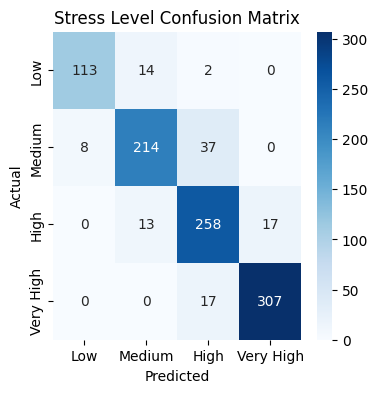

In [48]:
# Plot the confusion matrix
stress_order = ['Low', 'Medium', 'High', 'Very High']
cm = confusion_matrix(y_test_stress, y_pred_stress, labels=stress_order)

plt.figure(figsize=(4,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=stress_order, yticklabels=stress_order)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Stress Level Confusion Matrix")
plt.show()

The XGBoost classifier demonstrated strong predictive performance, correctly classifying approximately 89.2% of stress level instances. Classification errors were primarily limited to neighboring stress categories, while extreme misclassifications were virtually absent. Overall, the model effectively identifies stress patterns and provides reliable stress level predictions.

#### Train XGBoost Regressor (Mental_Health_Score)

In [49]:
# Use XGBoost Regressor Algorithm to predict Mental Health Score
xgb_mhs = Pipeline([('preprocessor', prepr_rf), 
                   ('regressor', XGBRegressor(n_estimators=200, random_state=42, n_jobs=-1))])
xgb_mhs.fit(x_train_mhs, y_train_mhs)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Age','Gender','Country',...,'Sleep_Hours_Per_Night', 'Screen_Nonscreen_Ratio','Unlocks_Per_Usage_Hour']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically 

#### Evaluate XGBoost Regressor (Mental_Health_Score)

In [50]:
# Predict the results
y_pred_mhs = xgb_mhs.predict(x_test_mhs)

In [51]:
# Calculate the Evaluation Parameters
mae = mean_absolute_error(y_test_mhs, y_pred_mhs)
rmse = root_mean_squared_error(y_test_mhs, y_pred_mhs)
r2 = r2_score(y_test_mhs, y_pred_mhs)
print(f'Mean Absolute Error: {round(mae,2)} \nRoot Mean Squared Error: {round(rmse,2)} \nR2 Score: {round(r2,2)}')

Mean Absolute Error: 0.29 
Root Mean Squared Error: 0.39 
R2 Score: 0.91


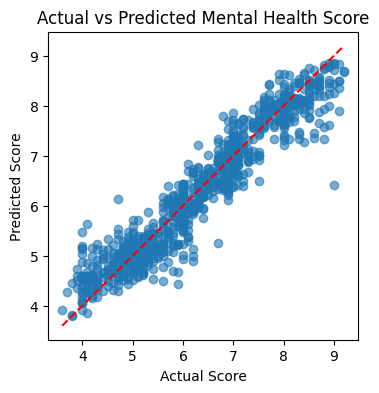

In [52]:
# Actual vs Prediction Plot
plt.figure(figsize=(4,4))
plt.scatter(y_test_mhs, y_pred_mhs, alpha=0.6)
plt.plot([y_test_mhs.min(), y_test_mhs.max()], [y_test_mhs.min(), y_test_mhs.max()], 'r--')
plt.xlabel("Actual Score")
plt.ylabel("Predicted Score")
plt.title("Actual vs Predicted Mental Health Score")
plt.show()

The XGBoost regressor achieved excellent predictive performance, explaining 91% of the variation in Mental Health Score while maintaining low prediction errors. The close alignment between actual and predicted values demonstrates the model's ability to accurately capture the relationship between digital behavior, lifestyle factors, and mental health outcomes.

### Cross Validation Score

In [53]:
# Calculate the cross validation metrics for Stress Level Prediction
cv_acc = cross_val_score(xgb_stress, x_train_stress, y_train_stress_enc, cv=5, scoring='accuracy', n_jobs=-1)
cv_f1 = cross_val_score(xgb_stress, x_train_stress, y_train_stress_enc, cv=5, scoring='f1_weighted', n_jobs=-1)
print("Mean Accuracy:", round(np.mean(cv_acc), 3))
print("Mean F1:", round(np.mean(cv_f1), 3))

Mean Accuracy: 0.859
Mean F1: 0.858


In [54]:
# Calculate the cross validation metrics for Mental Health Score Prediction
cv_r2 = cross_val_score(xgb_mhs, x_train_mhs, y_train_mhs, cv=5, scoring='r2', n_jobs=-1)
cv_rmse = -cross_val_score(xgb_mhs, x_train_mhs, y_train_mhs, cv=5, scoring='neg_root_mean_squared_error', 
                           n_jobs=-1)
print("Mean RMSE:", round(np.mean(cv_rmse), 3))
print("Mean R²:", round(np.mean(cv_r2), 3))

Mean RMSE: 0.416
Mean R²: 0.891


### Check for Overfitting

In [55]:
# For Stress Level
train_acc = xgb_stress.score(x_train_stress, y_train_stress_enc)
test_acc = xgb_stress.score(x_test_stress, y_test_stress_enc)
fit_stress = ('No Overfit' if abs(train_acc-test_acc) <= 0.04 else 
              'Slight Overfit' if abs(train_acc-test_acc) <= 0.08 else 
              'Moderate Overfit' if abs(train_acc-test_acc) <= 0.12 else 'Significant Overfit')
print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)
print('Fit:', fit_stress)

Train Accuracy: 1.0
Test Accuracy: 0.892
Fit: Moderate Overfit


In [56]:
# For Mental Health Score
train_pred = xgb_mhs.predict(x_train_mhs)
test_pred = xgb_mhs.predict(x_test_mhs)
train_r2 = r2_score(y_train_mhs, train_pred)
test_r2 = r2_score(y_test_mhs, test_pred)
fit_mhs = ('No Overfit' if abs(train_r2-test_r2) <= 0.04 else 
           'Slight Overfit' if abs(train_r2-test_r2) <= 0.08 else 
           'Moderate Overfit' if abs(train_r2-test_r2) <= 0.12 else 'Significant Overfit')
print("Train R²:", round(train_r2, 3))
print("Test R² :", round(test_r2, 3))
print('Fit:', fit_mhs)

Train R²: 0.994
Test R² : 0.913
Fit: Moderate Overfit


### Results Comparison between Random Forest and XGBoost

In [57]:
# For Stress Level Prediction
stress_results.append({'Model': 'XG Boost', 'Accuracy': round(accuracy,3), 
                       'Test F1 Score': round(test_f1,3), 'CV Mean Accuracy': round(np.mean(cv_acc),3),
                       'CV Mean F1 Score': round(np.mean(cv_f1),3), 'Train Accuracy': train_acc,
                       'Test Accuracy': test_acc, 'Overfitting': fit_stress})
stress_summary_df = pd.DataFrame(stress_results)
stress_summary_df

,Model,Accuracy,Test F1 Score,CV Mean Accuracy,CV Mean F1 Score,Train Accuracy,Test Accuracy,Overfitting
0,Random Forest,0.899,0.899,0.871,0.870,1.0,0.899,Moderate Overfit
1,XG Boost,0.892,0.892,0.859,0.858,1.0,0.892,Moderate Overfit


In [58]:
# For Mental Health Score Prediction
mhs_results.append({'Model': 'XG Boost', 'Mean Absolute Error': round(mae,3), 
                    'Root Mean Squared Error': round(rmse,2), 'R² Score': round(r2,2), 
                    'CV Mean RMSE': round(np.mean(cv_rmse), 3), 'CV Mean R² Score': round(np.mean(cv_r2), 3), 
                    'Train R² Score': round(train_r2, 3), 'Test R² Score': round(test_r2, 3), 
                    'Overfitting': fit_mhs})
mhs_summary_df = pd.DataFrame(mhs_results)
mhs_summary_df

,Model,Mean Absolute Error,Root Mean Squared Error,R² Score,CV Mean RMSE,CV Mean R² Score,Train R² Score,Test R² Score,Overfitting
0,Random Forest,0.285,0.40,0.91,0.416,0.891,0.987,0.912,Slight Overfit
1,XG Boost,0.291,0.39,0.91,0.416,0.891,0.994,0.913,Moderate Overfit


### Conclusion
Both algorithms ie. Random Forest and XG Boost performed exceptionally well on the dataset. Random Forest emerged as the stronger model for Stress Level classification, while both Random Forest and XGBoost achieved nearly identical results for Mental Health Score prediction. 

Cross-validation results confirmed that the models are stable and capable of generalizing to unseen data. The results suggest that screen usage behavior, sleep patterns, and related behavioral factors are strong predictors of both stress level and mental health outcomes.

Hyperparameter tuning needs to be performed on Random Forest Algorithm as the tuned Random Forest may reduce overfitting while maintaining or slightly improving test performance.

### Hyperparameter Tuning

In [59]:
# Using Randomized Search CV, find the best parameters for stress prediction model
param_grid_stress = {'classifier__n_estimators': [100, 200, 300, 500], 
                     'classifier__max_depth': [5, 10, 15, 20, None], 
                     'classifier__min_samples_split': [2, 5, 10, 20], 
                     'classifier__min_samples_leaf': [1, 2, 4, 8], 
                     'classifier__max_features': ['sqrt', 'log2', None]}
tuned_rf_stress = RandomizedSearchCV(estimator=rf_stress, param_distributions=param_grid_stress, n_iter=40, 
                                     scoring='f1_weighted', cv=5, random_state=42, n_jobs=-1, verbose=1)
tuned_rf_stress.fit(x_train_stress, y_train_stress)
print("Best Parameters:", tuned_rf_stress.best_params_)
print("\nBest CV F1 Score:", tuned_rf_stress.best_score_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best Parameters: {'classifier__n_estimators': 100, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 20}

Best CV F1 Score: 0.8657159599401509


In [60]:
# Using Randomized Search CV, find the best parameters for MHS prediction model
param_grid_mhs = {'regressor__n_estimators': [100, 200, 300, 500], 'regressor__max_depth': [5, 10, 15, 20, None], 
                  'regressor__min_samples_split': [2, 5, 10, 20], 'regressor__min_samples_leaf': [1, 2, 4, 8], 
                  'regressor__max_features': ['sqrt', 'log2', 0.7, 1.0]}
tuned_rf_mhs = RandomizedSearchCV(estimator=rf_mhs, param_distributions=param_grid_mhs, n_iter=40, 
                                  scoring='neg_root_mean_squared_error', cv=5, random_state=42, n_jobs=-1, 
                                  verbose=1)
tuned_rf_mhs.fit(x_train_mhs, y_train_mhs)
print("Best Parameters:", tuned_rf_mhs.best_params_)
print("\nBest CV RMSE:", -tuned_rf_mhs.best_score_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best Parameters: {'regressor__n_estimators': 500, 'regressor__min_samples_split': 2, 'regressor__min_samples_leaf': 1, 'regressor__max_features': 0.7, 'regressor__max_depth': 20}

Best CV RMSE: 0.41527301114288917


### Tuned Model Evaluation

#### 1. For Stress level Prediction

In [61]:
# Predict the output and calculate the accuracy and F1 score
best_rf_stress = tuned_rf_stress.best_estimator_
y_pred_stress = best_rf_stress.predict(x_test_stress)

accuracy = accuracy_score(y_test_stress, y_pred_stress)
test_f1 = f1_score(y_test_stress, y_pred_stress, average='weighted')
print("Accuracy:", round(accuracy, 3))
print("Test F1 Score:", round(test_f1, 3))

Accuracy: 0.892
Test F1 Score: 0.892


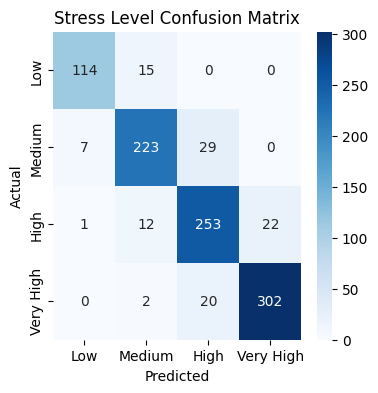

In [62]:
# Plot the confusion matrix
stress_order = ['Low', 'Medium', 'High', 'Very High']
cm = confusion_matrix(y_test_stress, y_pred_stress, labels=stress_order)

plt.figure(figsize=(4,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=stress_order, yticklabels=stress_order)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Stress Level Confusion Matrix")
plt.show()

In [63]:
# Calculate the cross validation metrics for Stress Level Prediction
cv_acc = cross_val_score(best_rf_stress, x_train_stress, y_train_stress, cv=5, scoring='accuracy', n_jobs=-1)
cv_f1 = cross_val_score(best_rf_stress, x_train_stress, y_train_stress, cv=5, scoring='f1_weighted', n_jobs=-1)

print("Mean Accuracy:", round(np.mean(cv_acc), 3))
print("Mean F1:", round(np.mean(cv_f1), 3))

Mean Accuracy: 0.866
Mean F1: 0.866


In [64]:
# Check for Overfitting
train_acc = best_rf_stress.score(x_train_stress, y_train_stress)
test_acc = best_rf_stress.score(x_test_stress, y_test_stress)
fit_stress = ('No Overfit' if abs(train_acc-test_acc) <= 0.04 else 
              'Slight Overfit' if abs(train_acc-test_acc) <= 0.08 else 
              'Moderate Overfit' if abs(train_acc-test_acc) <= 0.12 else 'Significant Overfit')
print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)
print('Fit:', fit_stress)

Train Accuracy: 0.9994997498749375
Test Accuracy: 0.892
Fit: Moderate Overfit


#### 2. For Mental Health Score Prediction

In [65]:
# Predict the output and calculate the MAE, RMSE and R2 Score
best_rf_mhs = tuned_rf_mhs.best_estimator_
y_pred_mhs = best_rf_mhs.predict(x_test_mhs)
mae = mean_absolute_error(y_test_mhs, y_pred_mhs)
rmse = root_mean_squared_error(y_test_mhs, y_pred_mhs)
r2 = r2_score(y_test_mhs, y_pred_mhs)
print(f'Mean Absolute Error: {round(mae,2)} \nRoot Mean Squared Error: {round(rmse,2)} \nR2 Score: {round(r2,2)}')

Mean Absolute Error: 0.29 
Root Mean Squared Error: 0.39 
R2 Score: 0.91


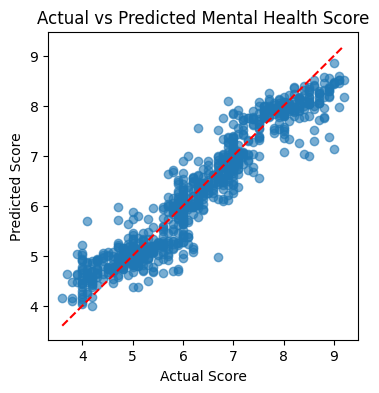

In [66]:
# Actual vs Prediction Plot
plt.figure(figsize=(4,4))
plt.scatter(y_test_mhs, y_pred_mhs, alpha=0.6)
plt.plot([y_test_mhs.min(), y_test_mhs.max()], [y_test_mhs.min(), y_test_mhs.max()], 'r--')
plt.xlabel("Actual Score")
plt.ylabel("Predicted Score")
plt.title("Actual vs Predicted Mental Health Score")
plt.show()

In [67]:
# Calculate the cross validation metrics for Mental Health Score Prediction
cv_r2 = cross_val_score(best_rf_mhs, x_train_mhs, y_train_mhs, cv=5, scoring='r2', n_jobs=-1)
cv_rmse = -cross_val_score(best_rf_mhs, x_train_mhs, y_train_mhs, cv=5, scoring='neg_root_mean_squared_error', 
                           n_jobs=-1)
print("Mean RMSE:", round(np.mean(cv_rmse), 3))
print("Mean R²:", round(np.mean(cv_r2), 3))

Mean RMSE: 0.415
Mean R²: 0.891


In [68]:
# Check for Overfitting
train_pred = best_rf_mhs.predict(x_train_mhs)
test_pred = best_rf_mhs.predict(x_test_mhs)
train_r2 = r2_score(y_train_mhs, train_pred)
test_r2 = r2_score(y_test_mhs, test_pred)
fit_mhs = ('No Overfit' if abs(train_r2-test_r2) <= 0.04 else 
           'Slight Overfit' if abs(train_r2-test_r2) <= 0.08 else 
           'Moderate Overfit' if abs(train_r2-test_r2) <= 0.12 else 'Significant Overfit')
print("Train R²:", round(train_r2, 3))
print("Test R² :", round(test_r2, 3))
print('Fit:', fit_mhs)

Train R²: 0.983
Test R² : 0.913
Fit: Slight Overfit


### Display the Final Results

In [69]:
# Display the results for Stress Level
stress_results.append({'Model': 'Tuned Random Forest', 'Accuracy': round(accuracy,3), 
                       'Test F1 Score': round(test_f1,3), 'CV Mean Accuracy': round(np.mean(cv_acc),3),
                       'CV Mean F1 Score': round(np.mean(cv_f1),3), 'Train Accuracy': train_acc,
                       'Test Accuracy': test_acc, 'Overfitting': fit_stress})
stress_summary_df = pd.DataFrame(stress_results)
stress_summary_df

,Model,Accuracy,Test F1 Score,CV Mean Accuracy,CV Mean F1 Score,Train Accuracy,Test Accuracy,Overfitting
0,Random Forest,0.899,0.899,0.871,0.870,1.0000,0.899,Moderate Overfit
1,XG Boost,0.892,0.892,0.859,0.858,1.0000,0.892,Moderate Overfit
2,Tuned Random Forest,0.892,0.892,0.866,0.866,0.9995,0.892,Moderate Overfit


In [70]:
# Display the results for Mental health Score
mhs_results.append({'Model': 'Tuned Random Forest', 'Mean Absolute Error': round(mae,3), 
                    'Root Mean Squared Error': round(rmse,2), 'R² Score': round(r2,2), 
                    'CV Mean RMSE': round(np.mean(cv_rmse), 3), 'CV Mean R² Score': round(np.mean(cv_r2), 3), 
                    'Train R² Score': round(train_r2, 3), 'Test R² Score': round(test_r2, 3), 
                    'Overfitting': fit_mhs})
mhs_summary_df = pd.DataFrame(mhs_results)
mhs_summary_df

,Model,Mean Absolute Error,Root Mean Squared Error,R² Score,CV Mean RMSE,CV Mean R² Score,Train R² Score,Test R² Score,Overfitting
0,Random Forest,0.285,0.40,0.91,0.416,0.891,0.987,0.912,Slight Overfit
1,XG Boost,0.291,0.39,0.91,0.416,0.891,0.994,0.913,Moderate Overfit
2,Tuned Random Forest,0.289,0.39,0.91,0.415,0.891,0.983,0.913,Slight Overfit


### Final Conclusion

#### For Stress Level : 
The baseline Random Forest Classifier was selected as the final model for Stress Level prediction. It achieved the highest test Accuracy and weighted F1 Score of 0.899, along with the highest cross-validation Accuracy (0.871) and F1 Score (0.870) among the evaluated models. Although some overfitting was observed, neither XGBoost nor hyperparameter tuning improved generalization performance. Therefore, the baseline Random Forest provides the best overall predictive performance for Stress Level classification.

#### For Mental Health Score :
The Tuned Random Forest Regressor was selected as the final model for Mental Health Score prediction. It achieved an R² of 0.913, RMSE of 0.39, and MAE of 0.289, while maintaining a cross-validation R² of 0.891. Its training R² decreased from 0.987 for the baseline model to 0.983 without reducing test performance, indicating slightly improved generalization. Therefore, the Tuned Random Forest provides a strong balance between predictive accuracy and model robustness.

### Model Deployment

In [73]:
# Save final models
joblib.dump(rf_stress, 'stress_level_model.pkl')
joblib.dump(best_rf_mhs, 'mental_health_score_model.pkl')

['mental_health_score_model.pkl']